<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/HW/01NAEX_Ex05_HW_Vesely.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 05: The $2^k$ factorial design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6.
Problem numbers follow the 8th edition.


## Learning goals

* Estimate the effects of a $2^k$ design from the table of plus and minus signs and relate them to the ANOVA and to the
  regression coefficients in coded variables (effect $= 2\hat\beta$).
* Fit the full model, refine it, test the lack of fit of the reduced model against the pure error and respect the hierarchy principle.
* Convert the model between coded and natural variables and draw response surface, contour and interaction plots.
* Compute standard errors and confidence intervals of the effects and use them to plan the number of replicates.
* Generate a randomized $2^k$ design in Python.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a balanced (replicated) $2^k$ design, computed
  directly from the table of signs.
* `design_2k()` - a $2^k$ design in standard (Yates) order with $n$ replicates and a random run order.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [38]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.factorplots import interaction_plot

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def design_2k(k, n_rep=1, names="ABCDEFGH", seed=None):
    """2^k factorial design in standard order, n_rep replicates and a random run order (column `run`)."""
    runs = itertools.product([-1, 1], repeat=k)
    std = pd.DataFrame([r[::-1] for r in runs], columns=list(names[:k]))      # the first factor changes fastest
    design = pd.concat([std] * n_rep, ignore_index=True)
    design.insert(0, "std_order", np.tile(np.arange(1, 2**k + 1), n_rep))
    design["rep"] = np.repeat(np.arange(1, n_rep + 1), 2**k)
    rng = np.random.default_rng(seed)
    design["run"] = rng.permutation(len(design)) + 1
    return design


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.6 * (2 + len(factors)), 3.3))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: chemical process ($2^2$ design)

Montgomery, Section 6.2: the effect of the reactant concentration (factor $A$: 15 and 25 %) and of the amount of catalyst
(factor $B$: 1 and 2 pounds) on the yield of a chemical process; $n = 3$ replicates, 12 runs in random order.

`yield` is a Python keyword, so a formula `yield ~ ...` does not work. We rename the column to `y`
(the alternative is to quote it in the formula: `Q("yield") ~ ...`).

In [39]:
chem = pd.read_csv(URL + "yield.txt", sep=r"\s+").rename(columns={"yield": "y"})
chem["A"] = chem["reactant"].map({"low": -1, "high": 1})
chem["B"] = chem["catalyst"].map({"low": -1, "high": 1})

# treatment totals (1), a, b, ab
totals = chem.groupby(["B", "A"])["y"].sum()
totals.index = ["(1)", "a", "b", "ab"]
print(totals)
chem.pivot_table(index="catalyst", columns="reactant", values="y", aggfunc=list)

(1)     80
a      100
b       60
ab      90
Name: y, dtype: int64


reactant,high,low
catalyst,,
high,"[31, 30, 29]","[18, 19, 23]"
low,"[36, 32, 32]","[28, 25, 27]"


### Effects from the treatment totals

$A = \frac{1}{2n}[ab + a - b - (1)]$, $B = \frac{1}{2n}[ab + b - a - (1)]$, $AB = \frac{1}{2n}[ab + (1) - a - b]$,
$SS = \text{Contrast}^2 / (4n)$.

In [40]:
one, a, b, ab = totals
n = 3
contrasts = {"A": ab + a - b - one, "B": ab + b - a - one, "A:B": ab + one - a - b}
for name, c in contrasts.items():
    print(f"{name:4s} contrast = {c:4d}, effect = {c / (2 * n):6.3f}, SS = {c**2 / (4 * n):7.3f}")

# the same with the helper function (works for any k)
effects_2k(chem, "y", ["A", "B"])

A    contrast =   50, effect =  8.333, SS = 208.333
B    contrast =  -30, effect = -5.000, SS =  75.000
A:B  contrast =   10, effect =  1.667, SS =   8.333


,contrast,effect,SS,coef
term,,,,
A,50,8.333333,208.333333,4.166667
B,-30,-5.000000,75.000000,-2.500000
A:B,10,1.666667,8.333333,0.833333


### ANOVA and model refinement

In [41]:
m_full = smf.ols("y ~ A * B", data=chem).fit()
display(sm.stats.anova_lm(m_full, typ=2))

m_red = smf.ols("y ~ A + B", data=chem).fit()
display(sm.stats.anova_lm(m_red, typ=2))

# F-test of the dropped interaction (the same as the F-test of AB in the full model)
sm.stats.anova_lm(m_red, m_full)

,sum_sq,df,F,PR(>F)
A,208.333333,1.0,53.191489,0.000084
B,75.000000,1.0,19.148936,0.002362
A:B,8.333333,1.0,2.127660,0.182776
Residual,31.333333,8.0,NaN,NaN


,sum_sq,df,F,PR(>F)
A,208.333333,1.0,47.268908,0.000073
B,75.000000,1.0,17.016807,0.002578
Residual,39.666667,9.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,9.0,39.666667,0.0,NaN,NaN,NaN
1,8.0,31.333333,1.0,8.333333,2.12766,0.182776


The concentration ($F_0 = 53.2$, $p < 0.001$) and the catalyst ($F_0 = 19.1$, $p = 0.002$) are significant, the interaction is not
($p = 0.18$). Coding the factors as $\pm 1$ numbers or as categories (`C(reactant)`) gives the same ANOVA.

### Regression model in coded and natural variables

In [42]:
print(m_full.summary().tables[1])
print(m_red.summary().tables[1])
print("effects / 2:", (effects_2k(chem, "y", ["A", "B"])["coef"]).round(4).to_dict())

c:\Users\Mateusz\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=12 observations were given.
  return hypotest_fun_in(*args, **kwds)
c:\Users\Mateusz\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=12 observations were given.
  return hypotest_fun_in(*args, **kwds)


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.5000      0.571     48.135      0.000      26.183      28.817
A              4.1667      0.571      7.293      0.000       2.849       5.484
B             -2.5000      0.571     -4.376      0.002      -3.817      -1.183
A:B            0.8333      0.571      1.459      0.183      -0.484       2.151
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.5000      0.606     45.377      0.000      26.129      28.871
A              4.1667      0.606      6.875      0.000       2.796       5.538
B             -2.5000      0.606     -4.125      0.003      -3.871      -1.129
effects / 2: {'A': 4.1667, 'B': -2.5, 'A:B': 0.8333}


The coefficients are one half of the effects and they do not change when $AB$ is removed (orthogonal design); only
$\hat\sigma$ and the standard errors change. The fitted reduced model is $\hat y = 27.5 + 4.167\,x_1 - 2.5\,x_2$.

In natural units: $x_1 = (Conc - 20)/5$, $x_2 = (Cat - 1.5)/0.5$.

In [43]:
chem["conc"] = 20 + 5 * chem["A"]
chem["cat"] = 1.5 + 0.5 * chem["B"]
m_nat = smf.ols("y ~ conc + cat", data=chem).fit()
print(m_nat.params)

# the same fitted values
print("same predictions:", np.allclose(m_nat.fittedvalues, m_red.fittedvalues))

Intercept    18.333333
conc          0.833333
cat          -5.000000
dtype: float64
same predictions: True


$\hat y = 18.33 + 0.833\,Conc - 5.0\,Cat$. The coefficients now depend on the units (per % and per pound).

### Response surface and contour plot

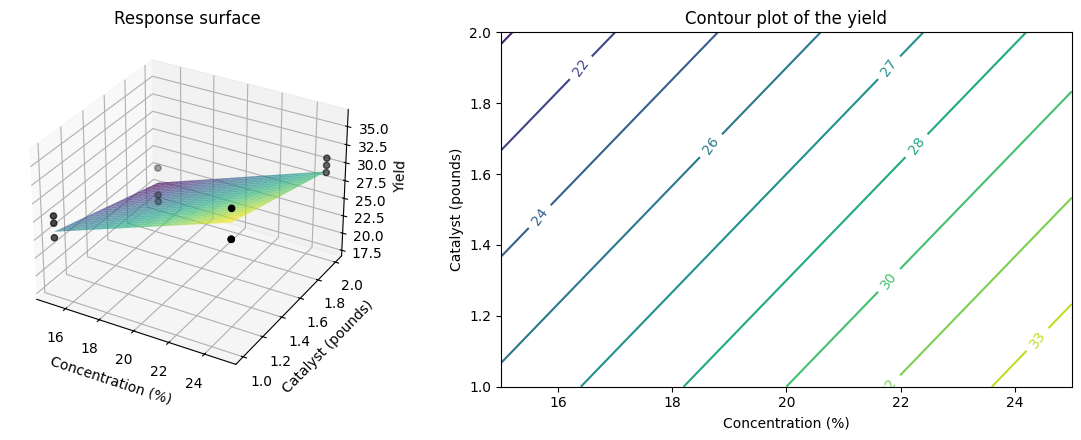

In [44]:
g1, g2 = np.meshgrid(np.linspace(15, 25, 51), np.linspace(1, 2, 51))
grid = pd.DataFrame({"conc": g1.ravel(), "cat": g2.ravel()})
z = m_nat.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.scatter(chem["conc"], chem["cat"], chem["y"], color="k")
ax1.set(xlabel="Concentration (%)", ylabel="Catalyst (pounds)", zlabel="Yield", title="Response surface")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=10, cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="Concentration (%)", ylabel="Catalyst (pounds)", title="Contour plot of the yield")
plt.tight_layout(); plt.show()

The first-order model is a plane: the contour lines are parallel straight lines. The yield increases towards high
concentration and low catalyst; the highest predicted yield inside the region is at $Conc = 25$ %, $Cat = 1$ pound.
Outside the region (and for possible curvature) the model says nothing.

### Model adequacy

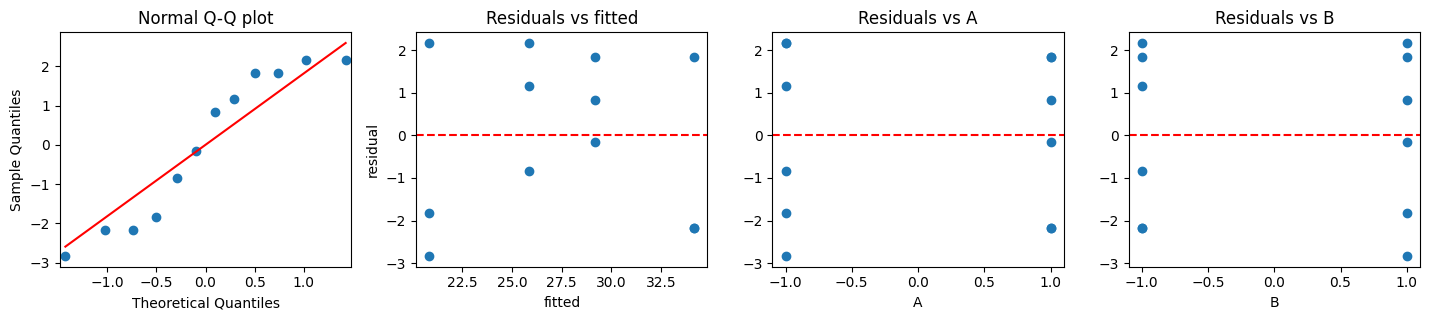

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.8817860959872293, pvalue=0.092391238336563)


In [45]:
residual_plots(m_red, chem, ["A", "B"])

## 2. Lecture example: plasma etch experiment ($2^3$ design)

Montgomery, Example 6.1: etch rate of silicon nitride (Å/min) in a single-wafer plasma etching tool. Factors: $A$ = gap between
the electrodes (0.8 and 1.2 cm), $B$ = C$_2$F$_6$ gas flow (125 and 200 SCCM), $C$ = RF power (275 and 325 W); $n = 2$ replicates.
The file has one row per treatment combination and the replicates in columns `R1`, `R2`; we reshape it to the long format.

In [46]:
plasma = pd.read_csv(URL + "plasma.txt", sep=r"\s+")
display(plasma.assign(total=plasma["R1"] + plasma["R2"]))

etch = plasma.melt(id_vars=["Run", "A", "B", "C"], value_vars=["R1", "R2"], var_name="rep", value_name="etch")
etch.head()

,Run,A,B,C,R1,R2,total
0,1,-1,-1,-1,550,604,1154
1,2,1,-1,-1,669,650,1319
2,3,-1,1,-1,633,601,1234
3,4,1,1,-1,642,635,1277
4,5,-1,-1,1,1037,1052,2089
5,6,1,-1,1,749,868,1617
6,7,-1,1,1,1075,1063,2138
7,8,1,1,1,729,860,1589


,Run,A,B,C,rep,etch
0,1,-1,-1,-1,R1,550
1,2,1,-1,-1,R1,669
2,3,-1,1,-1,R1,633
3,4,1,1,-1,R1,642
4,5,-1,-1,1,R1,1037


Note: the total of the treatment combination $bc$ is $1075 + 1063 = 2138$; the value 2178 printed in Table 6.4 of the book is a misprint.

### Effects from the table of signs

In [47]:
eff = effects_2k(etch, "etch", ["A", "B", "C"])
display(eff)

# the table of signs is the design matrix of the full coded model
full = smf.ols("etch ~ A * B * C", data=etch).fit()
X = pd.DataFrame(full.model.exog, columns=full.model.exog_names)
print(X.drop_duplicates().to_string(index=False))
print("X'X =\n", X.T @ X)

,contrast,effect,SS,coef
term,,,,
A,-813,-101.625,41310.5625,-50.8125
B,59,7.375,217.5625,3.6875
A:B,-199,-24.875,2475.0625,-12.4375
C,2449,306.125,374850.0625,153.0625
A:C,-1229,-153.625,94402.5625,-76.8125
B:C,-17,-2.125,18.0625,-1.0625
A:B:C,45,5.625,126.5625,2.8125


 Intercept    A    B  A:B    C  A:C  B:C  A:B:C
       1.0 -1.0 -1.0  1.0 -1.0  1.0  1.0   -1.0
       1.0  1.0 -1.0 -1.0 -1.0 -1.0  1.0    1.0
       1.0 -1.0  1.0 -1.0 -1.0  1.0 -1.0    1.0
       1.0  1.0  1.0  1.0 -1.0 -1.0 -1.0   -1.0
       1.0 -1.0 -1.0  1.0  1.0 -1.0 -1.0    1.0
       1.0  1.0 -1.0 -1.0  1.0  1.0 -1.0   -1.0
       1.0 -1.0  1.0 -1.0  1.0 -1.0  1.0   -1.0
       1.0  1.0  1.0  1.0  1.0  1.0  1.0    1.0
X'X =
            Intercept     A     B   A:B     C   A:C   B:C  A:B:C
Intercept       16.0   0.0   0.0   0.0   0.0   0.0   0.0    0.0
A                0.0  16.0   0.0   0.0   0.0   0.0   0.0    0.0
B                0.0   0.0  16.0   0.0   0.0   0.0   0.0    0.0
A:B              0.0   0.0   0.0  16.0   0.0   0.0   0.0    0.0
C                0.0   0.0   0.0   0.0  16.0   0.0   0.0    0.0
A:C              0.0   0.0   0.0   0.0   0.0  16.0   0.0    0.0
B:C              0.0   0.0   0.0   0.0   0.0   0.0  16.0    0.0
A:B:C            0.0   0.0   0.0   0.0   0.0   0.

The columns of the table of signs are orthogonal ($X^TX = 16\,I$). The large effects are $C$ (power, $+306$), $AC$ ($-154$)
and $A$ (gap, $-102$).

### ANOVA of the full model

In [48]:
sm.stats.anova_lm(full, typ=2)

,sum_sq,df,F,PR(>F)
A,41310.5625,1.0,18.339364,0.002679
B,217.5625,1.0,0.096584,0.763911
A:B,2475.0625,1.0,1.098776,0.325168
C,374850.0625,1.0,166.410505,0.000001
A:C,94402.5625,1.0,41.908965,0.000193
B:C,18.0625,1.0,0.008019,0.930849
A:B:C,126.5625,1.0,0.056186,0.818586
Residual,18020.5000,8.0,NaN,NaN


$A$, $C$ and $AC$ are significant; $B$ and all interactions with $B$ are not. With replicates, $MS_E = 2252.6$ (8 df) of the full
model is the **pure error**.

### Reduced model and lack of fit

In [49]:
red = smf.ols("etch ~ A * C", data=etch).fit()
display(sm.stats.anova_lm(red, typ=2))

# lack of fit of the reduced model = the dropped terms B, AB, BC, ABC, tested against the pure error
display(sm.stats.anova_lm(red, full))
print(red.summary().tables[1])
print(f"R2 = {red.rsquared:.4f}, adj. R2 = {red.rsquared_adj:.4f}  (full model: {full.rsquared:.4f}, {full.rsquared_adj:.4f})")

,sum_sq,df,F,PR(>F)
A,41310.5625,1.0,23.767029,3.816422e-04
C,374850.0625,1.0,215.660881,4.951261e-09
A:C,94402.5625,1.0,54.312222,8.620836e-06
Residual,20857.7500,12.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,12.0,20857.75,0.0,NaN,NaN,NaN
1,8.0,18020.50,4.0,2837.25,0.314891,0.860354


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    776.0625     10.423     74.458      0.000     753.353     798.772
A            -50.8125     10.423     -4.875      0.000     -73.522     -28.103
C            153.0625     10.423     14.685      0.000     130.353     175.772
A:C          -76.8125     10.423     -7.370      0.000     -99.522     -54.103
R2 = 0.9608, adj. R2 = 0.9509  (full model: 0.9661, 0.9364)


c:\Users\Mateusz\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=16 observations were given.
  return hypotest_fun_in(*args, **kwds)


The lack of fit is not significant ($F_0 = 0.31$, $p = 0.86$): the reduced model
$\hat y = 776.06 - 50.81\,x_1 + 153.06\,x_3 - 76.81\,x_1x_3$ is adequate. It explains $R^2 = 96.1$ % of the variability;
$R^2_{adj}$ increased from 0.936 to 0.951.

### Standard errors and confidence intervals of the effects

$V(\text{Effect}) = \sigma^2 / (n2^{k-2})$; the intervals of the effects are twice the intervals of the coded coefficients.

In [50]:
n, k = 2, 3
se_eff = np.sqrt(full.mse_resid / (n * 2**(k - 2)))
t = stats.t.ppf(0.975, full.df_resid)
print(f"se(effect) = {se_eff:.2f}, t = {t:.3f}, half-width = {t * se_eff:.2f}")

ci = 2 * full.conf_int().drop("Intercept")
ci.columns = ["lower", "upper"]
ci.insert(0, "effect", 2 * full.params.drop("Intercept"))
ci.round(2)

se(effect) = 23.73, t = 2.306, half-width = 54.72


,effect,lower,upper
A,-101.62,-156.35,-46.90
B,7.37,-47.35,62.10
A:B,-24.87,-79.60,29.85
C,306.13,251.40,360.85
A:C,-153.62,-208.35,-98.90
B:C,-2.12,-56.85,52.60
A:B:C,5.62,-49.10,60.35


Only the intervals of $A$, $C$ and $AC$ exclude zero, in agreement with the ANOVA.

### Main effects and interaction plots

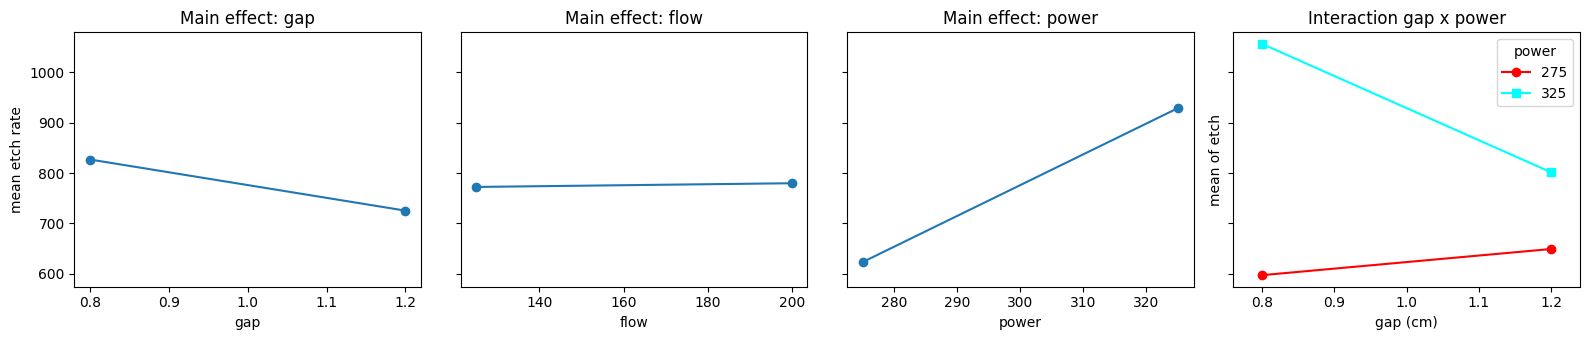

gap,0.8,1.2
power,,
275,597.00,649.0
325,1056.75,801.5


In [51]:
etch["gap"] = etch["A"].map({-1: 0.8, 1: 1.2})
etch["flow"] = etch["B"].map({-1: 125, 1: 200})
etch["power"] = etch["C"].map({-1: 275, 1: 325})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, f in zip(axes[:3], ["gap", "flow", "power"]):
    means = etch.groupby(f)["etch"].mean()
    ax.plot(means.index, means.values, "o-")
    ax.set(xlabel=f, title=f"Main effect: {f}")
axes[0].set_ylabel("mean etch rate")
interaction_plot(etch["gap"], etch["power"], etch["etch"], markers=["o", "s"], ax=axes[3])
axes[3].set(xlabel="gap (cm)", title="Interaction gap x power")
plt.tight_layout(); plt.show()

# averages at the corners of the gap x power square
etch.pivot_table(index="power", columns="gap", values="etch", aggfunc="mean")

Because of the $AC$ interaction the main effect of the gap must be interpreted together with the power: at 275 W a larger gap
increases the etch rate slightly (597 to 649 Å/min), at 325 W it decreases it by about 255 Å/min (1056.75 to 801.5).
The main effect $A = -101.6$ is the average of these two simple effects.

### Response surface in natural units

Intercept   -5415.3750
gap          4354.6875
power          21.4850
gap:power     -15.3625
dtype: float64


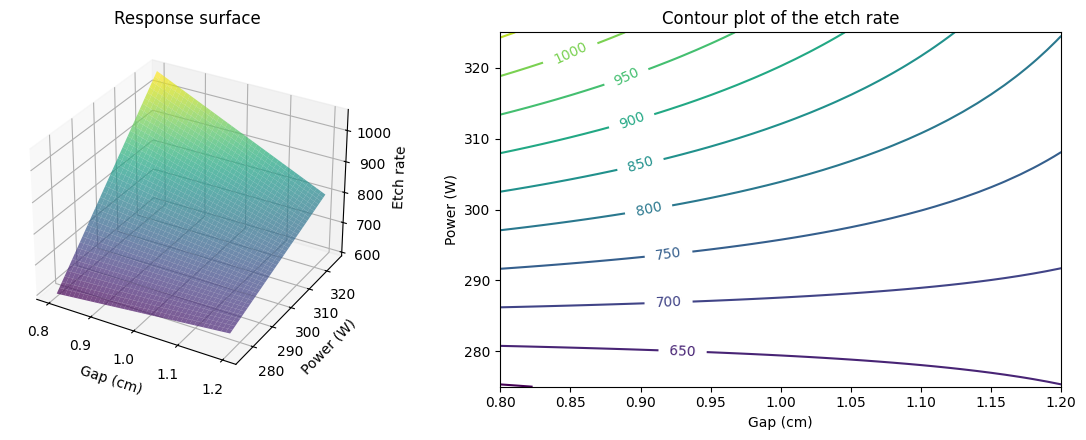

In [52]:
red_nat = smf.ols("etch ~ gap * power", data=etch).fit()
print(red_nat.params)

g1, g2 = np.meshgrid(np.linspace(0.8, 1.2, 41), np.linspace(275, 325, 41))
grid = pd.DataFrame({"gap": g1.ravel(), "power": g2.ravel()})
z = red_nat.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.set(xlabel="Gap (cm)", ylabel="Power (W)", zlabel="Etch rate", title="Response surface")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=np.arange(600, 1101, 50), cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="Gap (cm)", ylabel="Power (W)", title="Contour plot of the etch rate")
plt.tight_layout(); plt.show()

The interaction twists the plane, so the contour lines are curved. In natural units the coefficient of the gap is
$+4354.7$, although a larger gap decreases the etch rate everywhere in the region: with an interaction in the model it is the
slope at $Power = 0$ W. Interpret the coded model, use the natural one for predictions.

### Model adequacy

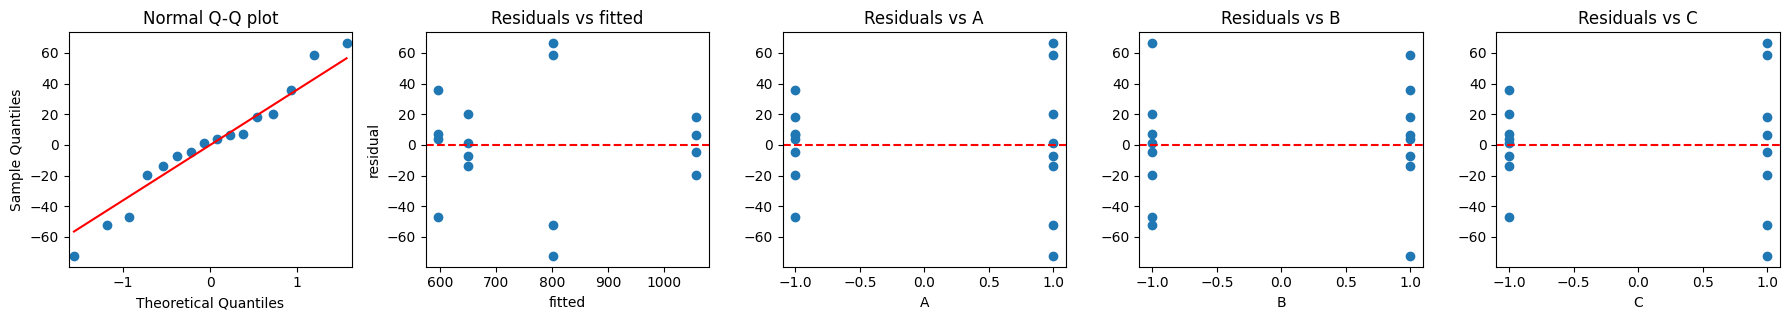

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9696763407594423, pvalue=0.8333388244618369)


In [53]:
residual_plots(red, etch, ["A", "B", "C"])

The normal Q-Q plot is acceptable and the residuals versus $B$ (not in the model) show no effect of the gas flow. But the
residuals versus the fitted values have a much larger spread at the fitted value of about 800, i.e. at high gap and high power.
Let us compare the variances in the four gap $\times$ power cells.

In [54]:
cells_AC = [d["etch"].to_numpy(dtype=float) for _, d in etch.groupby(["A", "C"])]
print(etch.groupby(["A", "C"])["etch"].agg(["mean", "std"]).round(1))
print(stats.levene(*cells_AC))
print(stats.bartlett(*cells_AC))

         mean   std
A  C               
-1 -1   597.0  34.5
    1  1056.8  16.2
 1 -1   649.0  14.7
    1   801.5  72.7
LeveneResult(statistic=11.222047088956753, pvalue=0.0008497048286857502)
BartlettResult(statistic=8.558062513256084, pvalue=0.03578204658179197)


The standard deviation at high gap and high power is about 73 Å/min, two to five times larger than in the other cells
(Levene $p < 0.001$). The conclusions about the means are not in danger (the effects are huge compared with the noise), but the
equal-variance assumption is violated and the gap may also affect the **variability** of the process (a dispersion effect,
Montgomery, Section 6.5 and Supplemental Material S6.5). In practice this would be a further argument for the small gap.

## 3. Generating a randomized $2^k$ design

`design_2k()` returns the design in standard order with a random run order. Map the codes to the real levels and add an empty
column for the response; sort by `run` to get the run sheet.

In [55]:
plan = design_2k(3, n_rep=2, names="ABC", seed=2026)
plan["gap_cm"] = plan["A"].map({-1: 0.8, 1: 1.2})
plan["flow_sccm"] = plan["B"].map({-1: 125, 1: 200})
plan["power_W"] = plan["C"].map({-1: 275, 1: 325})
plan["etch"] = np.nan                                   # to be filled in during the experiment
plan.sort_values("run")

,std_order,A,B,C,rep,run,gap_cm,flow_sccm,power_W,etch
5,6,1,-1,1,1,1,1.2,125,325,NaN
3,4,1,1,-1,1,2,1.2,200,275,NaN
4,5,-1,-1,1,1,3,0.8,125,325,NaN
10,3,-1,1,-1,2,4,0.8,200,275,NaN
14,7,-1,1,1,2,5,0.8,200,325,NaN
11,4,1,1,-1,2,6,1.2,200,275,NaN
2,3,-1,1,-1,1,7,0.8,200,275,NaN
13,6,1,-1,1,2,8,1.2,125,325,NaN
8,1,-1,-1,-1,2,9,0.8,125,275,NaN
6,7,-1,1,1,1,10,0.8,200,325,NaN


If each replicate is run on a different day (or with a different batch of material), randomize the order within each
replicate separately and analyse the replicates as blocks (Lecture 7).

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.5, 6.1, 6.2, 6.3,
  6.44 and 6.45**; Problem 6.8 is optional. Problems 6.1-6.3 and 6.44 use the same data.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; check the assumptions with
  residual plots; end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex05_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 1 November 2026** (the next lecture is on 2 November).

### Problem 6.5: router vibration

A router is used to cut locating notches on a printed circuit board. The vibration level at the surface of the board as it is
cut is considered to be a major source of dimensional variation in the notches. Two factors are thought to influence
vibration: bit size ($A$: 1/16 and 1/8 in.) and cutting speed ($B$: 40 and 90 rpm). Four boards are cut at each set of
conditions; the response is vibration measured as the resultant vector of three accelerometers.

| $A$ | $B$ | Treatment combination | I | II | III | IV |
|---|---|---|---|---|---|---|
| $-$ | $-$ | (1) | 18.2 | 18.9 | 12.9 | 14.4 |
| $+$ | $-$ | $a$ | 27.2 | 24.0 | 22.4 | 22.5 |
| $-$ | $+$ | $b$ | 15.9 | 14.5 | 15.1 | 14.2 |
| $+$ | $+$ | $ab$ | 41.0 | 43.9 | 36.3 | 39.9 |

In [2]:
router = pd.DataFrame({
    "A": np.repeat([-1, 1, -1, 1], 4),
    "B": np.repeat([-1, -1, 1, 1], 4),
    "vibration": [18.2, 18.9, 12.9, 14.4, 27.2, 24.0, 22.4, 22.5,
                  15.9, 14.5, 15.1, 14.2, 41.0, 43.9, 36.3, 39.9]})
router.pivot_table(index="B", columns="A", values="vibration", aggfunc=list)

NameError: name 'pd' is not defined

**Problem 6.5**

(a) Estimate the factor effects. Which effects appear to be large?

(b) Use the analysis of variance to confirm your conclusions for part (a) ($\alpha = 0.05$).

(c) Construct a normal probability plot of the residuals and plot the residuals versus the predicted vibration level.
Interpret these plots.

(d) Draw the $AB$ interaction plot and interpret it. What levels of bit size and speed would you recommend for routine operation?

**Solution:**

**(a) Effect estimates.** A $2^2$ design with $n = 4$ replicates ($N = 16$ runs). With the treatment totals $(1)$, $a$, $b$, $ab$
the effects are $A = \frac{1}{2n}[ab + a - b - (1)]$, $B = \frac{1}{2n}[ab + b - a - (1)]$, $AB = \frac{1}{2n}[ab + (1) - a - b]$ and
$SS = \text{Contrast}^2/(4n)$. The helper `effects_2k()` computes the same from the table of signs.

In [ ]:
# 6.5a: treatment totals and effect estimates from the table of signs
tot = router.groupby(["B", "A"])["vibration"].sum()
tot.index = ["(1)", "a", "b", "ab"]
print("treatment totals:", tot.round(1).to_dict())

eff65 = effects_2k(router, "vibration", ["A", "B"])
SST = ((router["vibration"] - router["vibration"].mean())**2).sum()
eff65["share of SS_T"] = eff65["SS"] / SST
display(eff65.round(3))
print(f"SS_T = {SST:.3f}, SS_E = {SST - eff65['SS'].sum():.3f} ({1 - eff65['SS'].sum() / SST:.1%} of SS_T)")

treatment totals: {'(1)': 64.4, 'a': 96.1, 'b': 59.7, 'ab': 161.1}


,contrast,effect,SS,coef,share of SS_T
term,,,,,
A,133.1,16.638,1107.226,8.319,0.648
B,60.3,7.538,227.256,3.769,0.133
A:B,69.7,8.712,303.631,4.356,0.178


SS_T = 1709.834, SS_E = 71.722 (4.2% of SS_T)


The bit size $A = 16.64$ is by far the largest effect (65 % of the total sum of squares); the interaction $AB = 8.71$ (18 %)
and the speed $B = 7.54$ (13 %) are also large compared with the residual 4 %. All three effects are positive: a larger bit
and a higher speed increase the vibration, and the increase is largest when both are at the high level.

**(b) ANOVA.** For each of the three effects $H_0$: effect $= 0$ against $H_1$: effect $\neq 0$ (equivalently $H_0: \beta_j = 0$
in the coded regression model), tested with the $F$-test of the full model `vibration ~ A * B`; the error mean square with
$2^2(n-1) = 12$ df comes from the replicates (pure error), $\alpha = 0.05$.

In [ ]:
# 6.5b: ANOVA of the full 2^2 model and the coded regression coefficients (= effects / 2)
m65 = smf.ols("vibration ~ A * B", data=router).fit()
display(sm.stats.anova_lm(m65, typ=2))
print(m65.summary().tables[1])
print(f"MS_E = {m65.mse_resid:.3f} (df = {m65.df_resid:.0f}), R2 = {m65.rsquared:.4f}, adj. R2 = {m65.rsquared_adj:.4f}")

,sum_sq,df,F,PR(>F)
A,1107.225625,1.0,185.251595,1.174669e-08
B,227.255625,1.0,38.022482,4.826292e-05
A:B,303.630625,1.0,50.800899,1.201078e-05
Residual,71.722500,12.0,NaN,NaN


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.8313      0.611     38.991      0.000      22.500      25.163
A              8.3188      0.611     13.611      0.000       6.987       9.650
B              3.7687      0.611      6.166      0.000       2.437       5.100
A:B            4.3562      0.611      7.127      0.000       3.025       5.688
MS_E = 5.977 (df = 12), R2 = 0.9581, adj. R2 = 0.9476


c:\Users\Mateusz\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=16 observations were given.
  return hypotest_fun_in(*args, **kwds)


| Term | $SS$ | $F_0$ | $p$-value | Decision |
|---|---|---|---|---|
| $A$ (bit size) | 1107.2 | 185.3 | $< 0.0001$ | reject $H_0$ |
| $B$ (speed) | 227.3 | 38.0 | $< 0.0001$ | reject $H_0$ |
| $AB$ | 303.6 | 50.8 | $< 0.0001$ | reject $H_0$ |

The ANOVA confirms (a): the sums of squares are exactly the $SS$ computed from the contrasts and all three effects are highly
significant at $\alpha = 0.05$. Nothing can be dropped, so the full model is the final model,
$\hat y = 23.83 + 8.32\,x_1 + 3.77\,x_2 + 4.36\,x_1 x_2$ (the coefficients are one half of the effects), $R^2 = 0.958$.

**(c) Residual analysis.** Normal Q-Q plot of the residuals, residuals versus the predicted vibration and versus the factors,
Shapiro-Wilk test of normality and Levene's test of equal variances in the four cells.

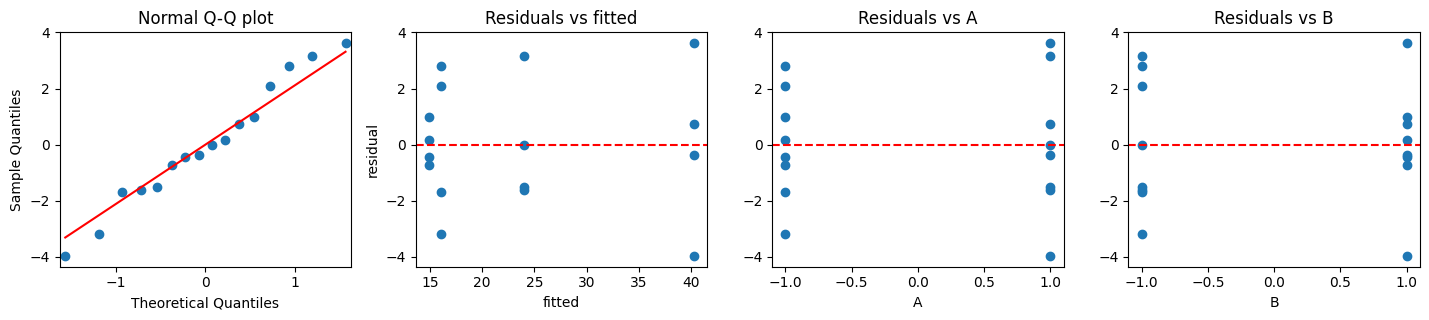

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9714201580754177, pvalue=0.8610570026553548)
        mean   std
A  B              
-1 -1  16.10  2.91
    1  14.92  0.75
 1 -1  24.02  2.24
    1  40.28  3.14
Levene (4 cells): LeveneResult(statistic=1.6315141061968699, pvalue=0.23418514877072538)


In [ ]:
# 6.5c: residual plots of the full model
residual_plots(m65, router, ["A", "B"])
print(router.groupby(["A", "B"])["vibration"].agg(["mean", "std"]).round(2))
print("Levene (4 cells):", stats.levene(*[d["vibration"].to_numpy(dtype=float) for _, d in router.groupby(["A", "B"])]))

The points in the normal Q-Q plot lie close to the line (Shapiro-Wilk $W = 0.971$, $p = 0.86$): normality is not rejected.
Residuals versus the predicted values form three vertical bands (predicted 14.9 and 16.1 for $b$ and $(1)$, 24.0 for $a$,
40.3 for $ab$); the spread is comparable in all bands (cell standard deviations 0.75 to 3.1, Levene $p = 0.23$) and there is
no funnel shape, so the variance does not grow with the vibration level. Residuals versus $A$ and $B$ show no pattern either.
The model assumptions are satisfied.

**(d) $AB$ interaction plot.** Cell means and the simple effects of the speed at each bit size; the simple effect of the speed
at the small bit is tested with a $t$-test using $MS_E$ of the model ($H_0$: $\mu_{b} = \mu_{(1)}$).

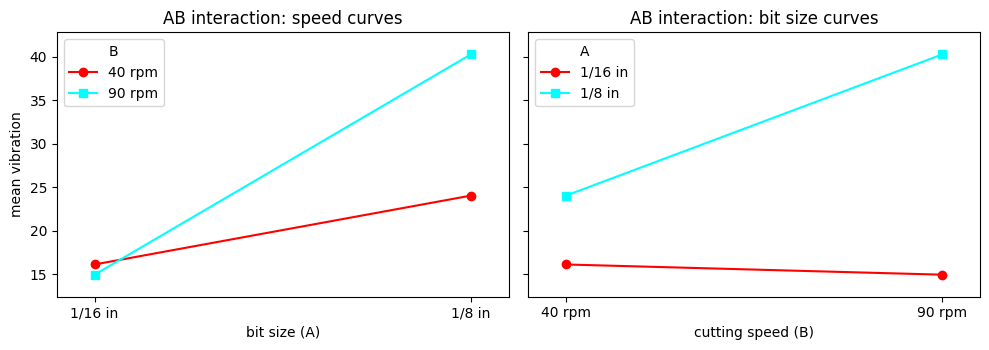

A,-1,1
B,,
-1,16.10,24.02
1,14.92,40.28


speed 90 - 40 rpm at small bit 1/16 in:  -1.18, t =  -0.68, p = 0.5096
speed 90 - 40 rpm at large bit 1/8 in:  16.25, t =   9.40, p = 0.0000


In [ ]:
# 6.5d: interaction plot, cell means and simple effects of the speed at each bit size
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
interaction_plot(router["A"], router["B"].map({-1: "40 rpm", 1: "90 rpm"}), router["vibration"],
                 markers=["o", "s"], ax=axes[0])
axes[0].set(xlabel="bit size (A)", ylabel="mean vibration", title="AB interaction: speed curves", xticks=[-1, 1],
            xticklabels=["1/16 in", "1/8 in"])
interaction_plot(router["B"], router["A"].map({-1: "1/16 in", 1: "1/8 in"}), router["vibration"],
                 markers=["o", "s"], ax=axes[1])
axes[1].set(xlabel="cutting speed (B)", ylabel="", title="AB interaction: bit size curves", xticks=[-1, 1],
            xticklabels=["40 rpm", "90 rpm"])
plt.tight_layout(); plt.show()

means65 = router.pivot_table(index="B", columns="A", values="vibration", aggfunc="mean")
display(means65.round(2))
se_diff = np.sqrt(2 * m65.mse_resid / 4)                          # se of a difference of two cell means, n = 4
for a_lvl, name in [(-1, "small bit 1/16 in"), (1, "large bit 1/8 in")]:
    d = means65.loc[1, a_lvl] - means65.loc[-1, a_lvl]
    t0 = d / se_diff
    print(f"speed 90 - 40 rpm at {name}: {d:6.2f}, t = {t0:6.2f}, p = {2 * stats.t.sf(abs(t0), m65.df_resid):.4f}")

The two lines are far from parallel, which is the significant $AB$ interaction. The main effect of the speed,
$B = 7.5$, is the average of these two simple effects ($-1.2$ and $+16.3$) and describes neither of them; the main effects
must not be interpreted separately here.

**Recommendation:** use the small bit (1/16 in). The large bit at least doubles the vibration whatever the speed. With the
small bit both speeds give the lowest vibration levels in the experiment, so the speed can be chosen on other grounds,
e.g. 90 rpm for a higher throughput.

**Conclusions (Problem 6.5)**

* Bit size ($A = 16.6$, $F_0 = 185$), speed ($B = 7.5$, $F_0 = 38$) and their interaction ($AB = 8.7$, $F_0 = 51$) are all
  significant ($p < 0.0001$); the full model $\hat y = 23.83 + 8.32\,x_1 + 3.77\,x_2 + 4.36\,x_1 x_2$ explains 96 % of the variability.
* The residual plots show no departure from normality ($p = 0.86$) or from constant variance ($p = 0.23$).
* Because of the interaction, the speed matters only with the large bit. Routine operation: small bit (1/16 in), speed free
  to choose (both 40 and 90 rpm give vibration around 15).

### Problem 6.8 (optional): virus growth

A bacteriologist is interested in the effects of two different culture media and two different times on the growth of a
particular virus. Six replicates of a $2^2$ design are run in random order.

| Time (h) | Culture medium 1 | Culture medium 2 |
|---|---|---|
| 12 | 21, 22, 23, 28, 20, 26 | 25, 26, 24, 25, 29, 27 |
| 18 | 37, 39, 38, 38, 35, 36 | 31, 34, 29, 33, 30, 35 |

In [61]:
virus = pd.DataFrame({
    "medium": np.repeat([1, 2, 1, 2], 6),
    "time": np.repeat([12, 12, 18, 18], 6),
    "growth": [21, 22, 23, 28, 20, 26, 25, 26, 24, 25, 29, 27,
               37, 39, 38, 38, 35, 36, 31, 34, 29, 33, 30, 35]})
virus.pivot_table(index="time", columns="medium", values="growth", aggfunc="mean")

medium,1,2
time,,
12,23.333333,26.0
18,37.166667,32.0


**Problem 6.8 (optional).** Analyse the data and draw appropriate conclusions. Is the effect of time the same for both media?
Analyse the residuals and comment on the model's adequacy.

**Solution:**

### Problem 6.1: tool life

An engineer is interested in the effects of cutting speed ($A$), tool geometry ($B$), and cutting angle ($C$) on the life
(in hours) of a machine tool. Two levels of each factor are chosen, and three replicates of a $2^3$ factorial design are run.
The results are as follows:

| $A$ | $B$ | $C$ | Treatment combination | I | II | III |
|---|---|---|---|---|---|---|
| $-$ | $-$ | $-$ | (1) | 22 | 31 | 25 |
| $+$ | $-$ | $-$ | $a$ | 32 | 43 | 29 |
| $-$ | $+$ | $-$ | $b$ | 35 | 34 | 50 |
| $+$ | $+$ | $-$ | $ab$ | 55 | 47 | 46 |
| $-$ | $-$ | $+$ | $c$ | 44 | 45 | 38 |
| $+$ | $-$ | $+$ | $ac$ | 40 | 37 | 36 |
| $-$ | $+$ | $+$ | $bc$ | 60 | 50 | 54 |
| $+$ | $+$ | $+$ | $abc$ | 39 | 41 | 47 |

In [64]:
tool = pd.read_csv(URL + "Problem_6_1.txt", sep=";")
tool.columns = ["A", "B", "C", "life"]        # cutting speed, tool geometry, cutting angle; life in hours
tool.pivot_table(index=["C", "B"], columns="A", values="life", aggfunc=list)

A                -1             1
C  B                             
-1 -1  [22, 31, 25]  [32, 43, 29]
    1  [35, 34, 50]  [55, 47, 46]
 1 -1  [44, 45, 38]  [40, 37, 36]
    1  [60, 50, 54]  [39, 41, 47]

**Problem 6.1**

(a) Estimate the factor effects. Which effects appear to be large?

(b) Use the analysis of variance to confirm your conclusions for part (a).

(c) Write down a regression model for predicting tool life (in hours) based on the results of this experiment.

(d) Analyze the residuals. Are there any obvious problems?

(e) On the basis of an analysis of main effect and interaction plots, what coded factor levels of $A$, $B$, and $C$ would
you recommend using?

**Solution:**

**(a) Effect estimates.** A $2^3$ design with $n = 3$ replicates ($N = 24$ runs): $A$ = cutting speed, $B$ = tool geometry,
$C$ = cutting angle. Effects from the table of signs: effect $= \text{Contrast}/(n 2^{k-1}) = \text{Contrast}/12$,
$SS = \text{Contrast}^2/(n 2^k) = \text{Contrast}^2/24$.

treatment totals: {'(1)': 78, 'a': 104, 'b': 119, 'ab': 148, 'c': 127, 'ac': 113, 'bc': 164, 'abc': 127}


,contrast,effect,SS,coef,share of SS_T
term,,,,,
A,4,0.333,0.667,0.167,0.000
B,136,11.333,770.667,5.667,0.368
A:B,-20,-1.667,16.667,-0.833,0.008
C,82,6.833,280.167,3.417,0.134
A:C,-106,-8.833,468.167,-4.417,0.223
B:C,-34,-2.833,48.167,-1.417,0.023
A:B:C,-26,-2.167,28.167,-1.083,0.013


SS_T = 2095.333, SS_E = 482.667 (23.0% of SS_T)


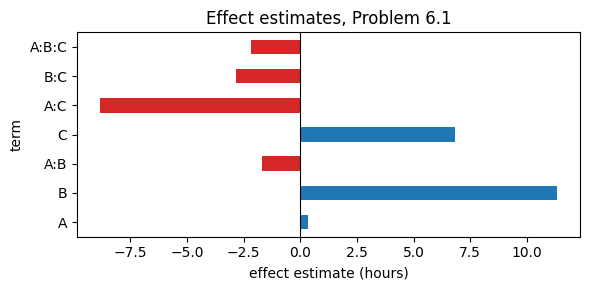

In [65]:
# 6.1a: treatment totals and the effect estimates from the table of signs
tot = tool.groupby(["C", "B", "A"])["life"].sum()
tot.index = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
print("treatment totals:", tot.to_dict())

eff61 = effects_2k(tool, "life", ["A", "B", "C"])
SST = ((tool["life"] - tool["life"].mean())**2).sum()
eff61["share of SS_T"] = eff61["SS"] / SST
display(eff61.round(3))
print(f"SS_T = {SST:.3f}, SS_E = {SST - eff61['SS'].sum():.3f} ({1 - eff61['SS'].sum() / SST:.1%} of SS_T)")

fig, ax = plt.subplots(figsize=(6, 3))
eff61["effect"].plot.barh(ax=ax, color=np.where(eff61["effect"] > 0, "C0", "C3"))
ax.axvline(0, color="k", lw=0.8); ax.set(xlabel="effect estimate (hours)", title="Effect estimates, Problem 6.1")
plt.tight_layout(); plt.show()

The tool geometry $B = 11.33$ h is the largest effect (37 % of $SS_T$), followed by the speed $\times$ angle interaction
$AC = -8.83$ (22 %) and the cutting angle $C = 6.83$ (13 %). The speed itself ($A = 0.33$) is practically zero and $AB = -1.67$,
$BC = -2.83$, $ABC = -2.17$ are small (together 4 % of $SS_T$, compared with 23 % residual).

**(b) ANOVA.** For every effect $H_0$: effect $= 0$ against $H_1$: effect $\neq 0$, $F$-tests of the full model `life ~ A * B * C`
with the pure-error mean square ($2^3(n - 1) = 16$ df), $\alpha = 0.05$.

In [66]:
# 6.1b: ANOVA of the full 2^3 model
full61 = smf.ols("life ~ A * B * C", data=tool).fit()
display(sm.stats.anova_lm(full61, typ=2))
print(f"MS_E (pure error) = {full61.mse_resid:.3f} with {full61.df_resid:.0f} df, R2 = {full61.rsquared:.4f}, adj. R2 = {full61.rsquared_adj:.4f}")

,sum_sq,df,F,PR(>F)
A,0.666667,1.0,0.022099,0.883680
B,770.666667,1.0,25.546961,0.000117
A:B,16.666667,1.0,0.552486,0.468078
C,280.166667,1.0,9.287293,0.007679
A:C,468.166667,1.0,15.519337,0.001172
B:C,48.166667,1.0,1.596685,0.224475
A:B:C,28.166667,1.0,0.933702,0.348282
Residual,482.666667,16.0,NaN,NaN


MS_E (pure error) = 30.167 with 16 df, R2 = 0.7696, adj. R2 = 0.6689


| Term | $SS$ | $F_0$ | $p$-value | Decision |
|---|---|---|---|---|
| $A$ | 0.67 | 0.02 | 0.88 | do not reject |
| $B$ | 770.67 | 25.55 | 0.0001 | reject |
| $C$ | 280.17 | 9.29 | 0.0077 | reject |
| $AB$ | 16.67 | 0.55 | 0.47 | do not reject |
| $AC$ | 468.17 | 15.52 | 0.0012 | reject |
| $BC$ | 48.17 | 1.60 | 0.22 | do not reject |
| $ABC$ | 28.17 | 0.93 | 0.35 | do not reject |

The ANOVA confirms (a): $B$, $C$ and $AC$ are significant at $\alpha = 0.05$, $A$, $AB$, $BC$ and $ABC$ are not.
$MS_E = 30.17$ (16 df) is the pure error.

**(c) Regression model.** Keep $B$, $C$ and $AC$; by the hierarchy principle the main effect $A$ is kept as well because it is
part of the significant interaction $AC$ (the nonhierarchical alternative without $A$ is examined in Problem 6.44). The adequacy
of the reduced model `life ~ A + B + C + A:C` is checked with the lack-of-fit test of the dropped terms $AB$, $BC$, $ABC$ against
the pure error ($H_0$: the dropped terms are zero).

In [67]:
# 6.1c: reduced hierarchical model, lack-of-fit test and the fitted regression equation in coded variables
red61 = smf.ols("life ~ A + B + C + A:C", data=tool).fit()
display(sm.stats.anova_lm(red61, typ=2))
display(sm.stats.anova_lm(red61, full61))            # lack of fit: AB, BC, ABC vs pure error
print(red61.summary().tables[1])
b = red61.params
print(f"life_hat = {b['Intercept']:.3f} + {b['A']:.3f} x1 + {b['B']:.3f} x2 + {b['C']:.3f} x3 {b['A:C']:+.3f} x1 x3")
print(f"R2 = {red61.rsquared:.4f}, adj. R2 = {red61.rsquared_adj:.4f}, MS_E = {red61.mse_resid:.3f} ({red61.df_resid:.0f} df)")
print("coefficients = effects / 2:", (eff61["coef"][["A", "B", "C", "A:C"]]).round(4).to_dict())

,sum_sq,df,F,PR(>F)
A,0.666667,1.0,0.022003,0.883641
B,770.666667,1.0,25.436016,0.000072
C,280.166667,1.0,9.246960,0.006724
A:C,468.166667,1.0,15.451940,0.000897
Residual,575.666667,19.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,19.0,575.666667,0.0,NaN,NaN,NaN
1,16.0,482.666667,3.0,93.0,1.027624,0.406692


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     40.8333      1.124     36.342      0.000      38.482      43.185
A              0.1667      1.124      0.148      0.884      -2.185       2.518
B              5.6667      1.124      5.043      0.000       3.315       8.018
C              3.4167      1.124      3.041      0.007       1.065       5.768
A:C           -4.4167      1.124     -3.931      0.001      -6.768      -2.065
life_hat = 40.833 + 0.167 x1 + 5.667 x2 + 3.417 x3 -4.417 x1 x3
R2 = 0.7253, adj. R2 = 0.6674, MS_E = 30.298 (19 df)
coefficients = effects / 2: {'A': 0.1667, 'B': 5.6667, 'C': 3.4167, 'A:C': -4.4167}


The lack of fit is not significant ($F_0 = 1.03$ with 3 and 16 df, $p = 0.41$): the three dropped terms are not needed. Because the
design is orthogonal the coefficients do not change when terms are dropped and equal one half of the effects. The regression
model for the tool life (hours) in coded variables $x_1$ (speed), $x_2$ (geometry), $x_3$ (angle) is

$$\hat y = 40.83 + 0.17\,x_1 + 5.67\,x_2 + 3.42\,x_3 - 4.42\,x_1 x_3,$$

with $R^2 = 0.725$, $R^2_{adj} = 0.667$ and $\hat\sigma^2 = MS_E = 30.30$ (19 df); the problem gives no natural levels of the
factors, so the model stays in coded units.

**(d) Residual analysis** of the reduced model: normal Q-Q plot, residuals versus the fitted values and versus each factor
(including the dropped interactions implicitly, since $A$, $B$, $C$ are all shown), Shapiro-Wilk and Levene's tests.

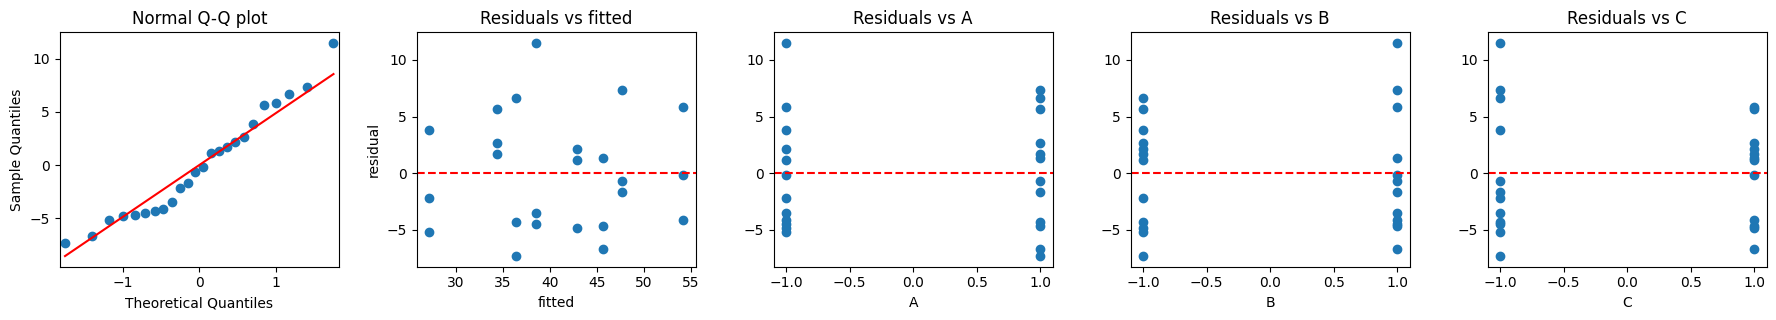

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9530015025955677, pvalue=0.3142911290594741)
Levene (8 cells): LeveneResult(statistic=0.23956496178718403, pvalue=0.9685644664370691)
largest standardized residual: 2.35 at run 8 {'A': -1, 'B': 1, 'C': -1, 'life': 50}


In [68]:
# 6.1d: residual plots of the reduced model
residual_plots(red61, tool, ["A", "B", "C"])
cells61 = [d["life"].to_numpy(dtype=float) for _, d in tool.groupby(["A", "B", "C"])]
print("Levene (8 cells):", stats.levene(*cells61))
r_std = red61.get_influence().resid_studentized_internal
print("largest standardized residual:", r_std.round(2).max(), "at run", int(np.argmax(r_std)),
      tool.iloc[int(np.argmax(r_std))].to_dict())

The Q-Q plot is roughly linear with a slightly heavier upper tail: the largest residual ($+11.5$ h, standardized 2.35) belongs to
the third replicate of the treatment $b$ (life 50 h against 35 and 34 h in the same cell, fitted value 38.5 h). Shapiro-Wilk does not reject normality
($W = 0.953$, $p = 0.31$). Residuals versus the fitted values and versus $A$, $B$, $C$ show no funnel or other pattern and the
cell variances are homogeneous (Levene $p = 0.97$). There are no obvious problems; the one larger observation would be worth
re-checking in the lab records but is not an outlier.

**(e) Main effect and interaction plots.** Means at the two levels of each factor, the $AC$ interaction (the only significant
one) and, for comparison, the nonsignificant $AB$ and $BC$ interactions.

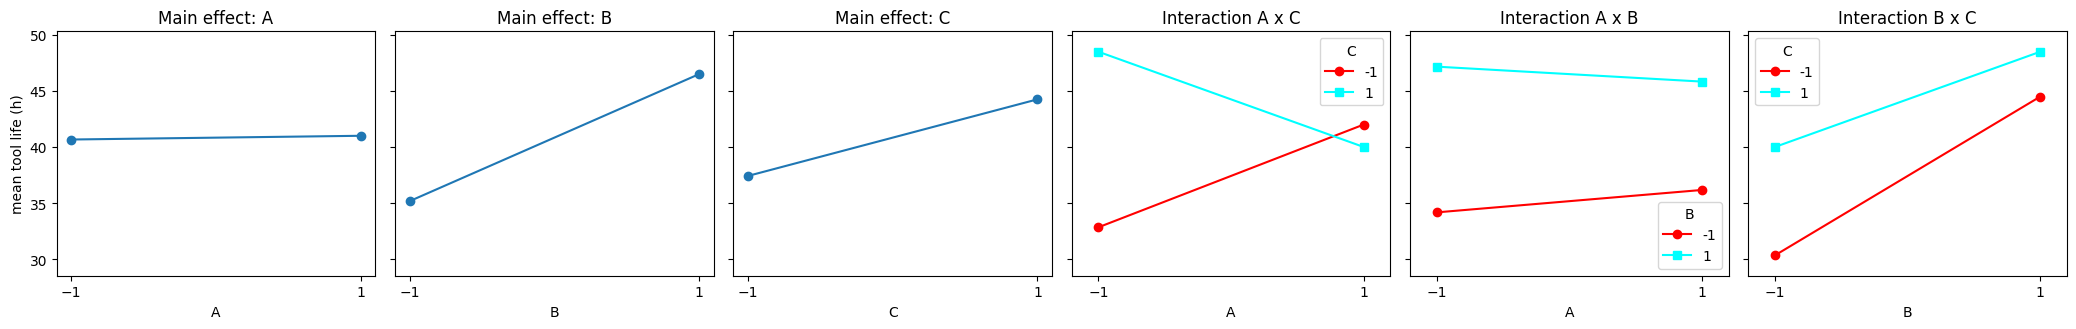

A x C cell means:


A,-1,1
C,,
-1,32.83,42.0
1,48.50,40.0


means of the 8 treatment combinations (observed) and the predictions of the reduced model:


,A,B,C,observed mean,predicted
3,-1,1,1,54.67,54.17
6,1,1,-1,49.33,47.67
7,1,1,1,42.33,45.67
1,-1,-1,1,42.33,42.83
2,-1,1,-1,39.67,38.50
4,1,-1,-1,34.67,36.33
5,1,-1,1,37.67,34.33
0,-1,-1,-1,26.00,27.17


In [69]:
# 6.1e: main effect plots, interaction plots and cell means
fig, axes = plt.subplots(1, 6, figsize=(21, 3.4), sharey=True)
for ax, f in zip(axes[:3], ["A", "B", "C"]):
    mns = tool.groupby(f)["life"].mean()
    ax.plot(mns.index, mns.values, "o-")
    ax.set(xlabel=f, title=f"Main effect: {f}", xticks=[-1, 1])
axes[0].set_ylabel("mean tool life (h)")
for ax, (x, tr) in zip(axes[3:], [("A", "C"), ("A", "B"), ("B", "C")]):
    interaction_plot(tool[x], tool[tr], tool["life"], markers=["o", "s"], ax=ax)
    ax.set(xlabel=x, ylabel="", title=f"Interaction {x} x {tr}", xticks=[-1, 1])
plt.tight_layout(); plt.show()

print("A x C cell means:")
display(tool.pivot_table(index="C", columns="A", values="life", aggfunc="mean").round(2))
print("means of the 8 treatment combinations (observed) and the predictions of the reduced model:")
corners = tool.groupby(["A", "B", "C"], as_index=False)["life"].mean().rename(columns={"life": "observed mean"})
corners["predicted"] = red61.predict(corners[["A", "B", "C"]])
display(corners.round(2).sort_values("predicted", ascending=False))

* **Tool geometry $B$:** the high level increases the mean life from 35.2 to 46.5 h, and the $AB$ and $BC$ lines are almost
  parallel, so $B = +1$ is recommended regardless of the other factors.
* **Speed $A$ and angle $C$:** the main effect of $A$ is zero only on average. At low speed ($A = -1$) the high cutting angle
  raises the life from 32.8 to 48.5 h; at high speed ($A = +1$) the angle does nothing (42.0 versus 40.0 h). Equivalently, at the
  low angle a higher speed helps, at the high angle it hurts.
* The best combination is $A = -1$, $B = +1$, $C = +1$ (treatment $bc$: observed mean 54.7 h, predicted 54.2 h); the runner-up
  $A = +1$, $B = +1$, $C = -1$ (47.7 h) is clearly worse.

**Recommendation:** low cutting speed, high tool geometry, high cutting angle ($x_1 = -1$, $x_2 = +1$, $x_3 = +1$).

**Conclusions (Problem 6.1)**

* Tool geometry ($B = 11.3$ h, $F_0 = 25.5$, $p = 0.0001$), cutting angle ($C = 6.8$ h, $F_0 = 9.3$, $p = 0.008$) and the
  speed $\times$ angle interaction ($AC = -8.8$ h, $F_0 = 15.5$, $p = 0.001$) are significant; the speed alone and the remaining
  interactions are not.
* Reduced model $\hat y = 40.83 + 0.17\,x_1 + 5.67\,x_2 + 3.42\,x_3 - 4.42\,x_1 x_3$ (lack of fit $p = 0.41$, $R^2_{adj} = 0.67$),
  residuals without problems.
* Recommended levels: $A = -1$, $B = +1$, $C = +1$, expected tool life about 54 h.

**Problem 6.2.** Reconsider part (c) of Problem 6.1. Use the regression model to generate response surface and contour plots
of the tool life response. Interpret these plots. Do they provide insight regarding the desirable operating conditions for
this process? (The problem gives no natural levels, so draw the plots in the coded variables; with three factors fix the
third one at $-1$ and at $+1$.)

**Solution:**

With $x_3$ fixed, the model of Problem 6.1(c) is a plane in $(x_1, x_2)$ whose slope in $x_1$ depends on $x_3$:

$x_3 = -1$: $\hat y = 37.42 + 4.58\,x_1 + 5.67\,x_2$, $\qquad$ $x_3 = +1$: $\hat y = 44.25 - 4.25\,x_1 + 5.67\,x_2$.

Response surfaces and contour plots in the coded variables over the experimental region $[-1, 1]^2$, plus the $x_1 \times x_3$
plane at $x_2 = +1$ (the recommended geometry), where the interaction twists the surface.

x3 = -1:  life_hat = 37.417 +4.583 x1 +5.667 x2
x3 = +1:  life_hat = 44.250 -4.250 x1 +5.667 x2


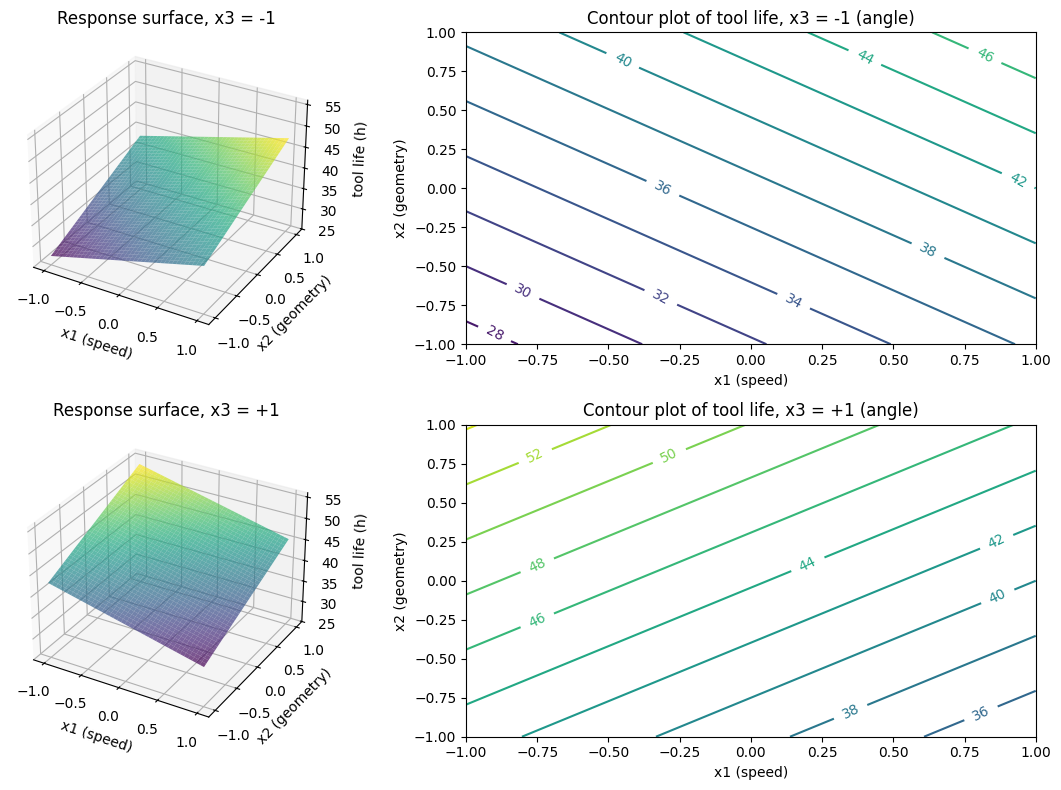

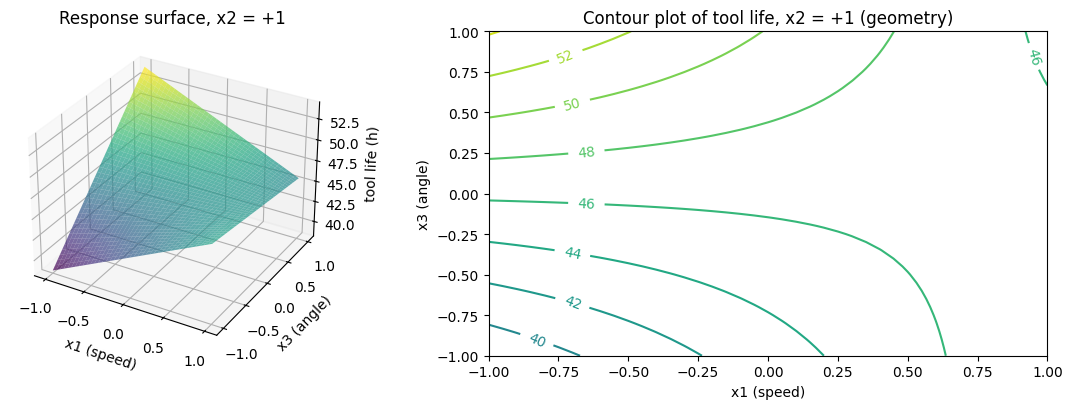

In [70]:
# 6.2: response surfaces and contour plots of the reduced model in coded units
b = red61.params
for x3 in (-1, 1):
    print(f"x3 = {x3:+d}:  life_hat = {b['Intercept'] + b['C'] * x3:.3f} {b['A'] + b['A:C'] * x3:+.3f} x1 {b['B']:+.3f} x2")

g1, g2 = np.meshgrid(np.linspace(-1, 1, 41), np.linspace(-1, 1, 41))
levels = np.arange(26, 58, 2)
fig = plt.figure(figsize=(12, 8))
for i, x3 in enumerate((-1, 1)):
    grid = pd.DataFrame({"A": g1.ravel(), "B": g2.ravel(), "C": x3})
    z = red61.predict(grid).to_numpy().reshape(g1.shape)
    ax1 = fig.add_subplot(2, 2, 2 * i + 1, projection="3d")
    ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
    ax1.set(xlabel="x1 (speed)", ylabel="x2 (geometry)", zlabel="tool life (h)", title=f"Response surface, x3 = {x3:+d}", zlim=(25, 56))
    ax2 = fig.add_subplot(2, 2, 2 * i + 2)
    cs = ax2.contour(g1, g2, z, levels=levels, cmap="viridis")
    ax2.clabel(cs, fmt="%.0f")
    ax2.set(xlabel="x1 (speed)", ylabel="x2 (geometry)", title=f"Contour plot of tool life, x3 = {x3:+d} (angle)")
plt.tight_layout(); plt.show()

# the twisted plane: x1 x x3 at x2 = +1
grid = pd.DataFrame({"A": g1.ravel(), "B": 1, "C": g2.ravel()})
z = red61.predict(grid).to_numpy().reshape(g1.shape)
fig = plt.figure(figsize=(12, 4.2))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.set(xlabel="x1 (speed)", ylabel="x3 (angle)", zlabel="tool life (h)", title="Response surface, x2 = +1")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=levels, cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="x1 (speed)", ylabel="x3 (angle)", title="Contour plot of tool life, x2 = +1 (geometry)")
plt.tight_layout(); plt.show()

**Interpretation.** In the $x_1 \times x_2$ plane the surfaces are planes and the contours parallel straight lines: for a fixed
angle the model is first order in the speed and the geometry. The tool life always increases with $x_2$ (geometry), by the same
amount $2 \cdot 5.67 = 11.3$ h across the region. The direction in $x_1$ reverses with the angle: at the low angle ($x_3 = -1$)
the life increases with the speed (slope $+4.58$), at the high angle ($x_3 = +1$) it decreases (slope $-4.25$), and the whole
surface at $x_3 = +1$ is higher. In the $x_1 \times x_3$ plane at $x_2 = +1$ the contours are curved (hyperbolas): this is the
$AC$ interaction, a twisted plane with the ridge of long tool life running from (low speed, high angle) to
(high speed, low angle), the former being higher.

The plots do provide insight into the desirable operating conditions: the longest life inside the experimental region,
$\hat y = 54.2$ h, is at the corner $x_1 = -1$, $x_2 = +1$, $x_3 = +1$ (low speed, high geometry, high angle), in agreement with
Problem 6.1(e). Since the model is a first-order model with an interaction, it says nothing about curvature or an optimum
beyond the cube; the plots suggest that moving further towards lower speed and higher angle/geometry could be explored next.

**Conclusions (Problem 6.2)**

* For fixed $x_3$ the fitted surface is a plane with parallel contours; the $AC$ interaction shows up as a reversed slope in $x_1$
  between $x_3 = -1$ and $x_3 = +1$ and as curved contours in the $x_1 \times x_3$ plane.
* The desirable operating region is low speed, high geometry, high angle (predicted life about 54 h).

**Problem 6.3.** Find the standard error of the factor effects and approximate 95 percent confidence limits for the factor
effects in Problem 6.1. Do the results of this analysis agree with the conclusions from the analysis of variance?

**Solution:**

Each effect is a difference of two averages of $n 2^{k-1} = 12$ observations, so $V(\text{Effect}) = \sigma^2 / (n 2^{k-2}) = \sigma^2 / 6$,
estimated with the pure-error $MS_E = 30.17$ (16 df) of the full model. The 95 % confidence limits are
$\text{Effect} \pm t_{0.025, 16}\, se(\text{Effect})$; Montgomery's approximate limits use $\pm 2\,se$ instead of the $t$ quantile.
The intervals of the effects are twice the intervals of the coded regression coefficients of the full model.

In [71]:
# 6.3: standard error of the effects and 95 % confidence limits
n, k = 3, 3
se_eff = np.sqrt(full61.mse_resid / (n * 2**(k - 2)))
t_q = stats.t.ppf(0.975, full61.df_resid)
print(f"MS_E = {full61.mse_resid:.3f}, se(effect) = sqrt(MS_E / (n 2^(k-2))) = {se_eff:.4f}")
print(f"t(0.975, {full61.df_resid:.0f}) = {t_q:.4f}: half-width = {t_q * se_eff:.3f};  approximate 2 se = {2 * se_eff:.3f}")

ci63 = 2 * full61.conf_int().drop("Intercept")
ci63.columns = ["lower (t)", "upper (t)"]
ci63.insert(0, "effect", 2 * full61.params.drop("Intercept"))
ci63["lower (2se)"] = ci63["effect"] - 2 * se_eff
ci63["upper (2se)"] = ci63["effect"] + 2 * se_eff
ci63["excludes 0"] = (ci63["lower (t)"] > 0) | (ci63["upper (t)"] < 0)
ci63["ANOVA p"] = sm.stats.anova_lm(full61, typ=2)["PR(>F)"].drop("Residual").round(4)
display(ci63.round(3))

MS_E = 30.167, se(effect) = sqrt(MS_E / (n 2^(k-2))) = 2.2423
t(0.975, 16) = 2.1199: half-width = 4.753;  approximate 2 se = 4.485


,effect,lower (t),upper (t),lower (2se),upper (2se),excludes 0,ANOVA p
A,0.333,-4.420,5.087,-4.151,4.818,False,0.884
B,11.333,6.580,16.087,6.849,15.818,True,0.000
A:B,-1.667,-6.420,3.087,-6.151,2.818,False,0.468
C,6.833,2.080,11.587,2.349,11.318,True,0.008
A:C,-8.833,-13.587,-4.080,-13.318,-4.349,True,0.001
B:C,-2.833,-7.587,1.920,-7.318,1.651,False,0.224
A:B:C,-2.167,-6.920,2.587,-6.651,2.318,False,0.348


$se(\text{Effect}) = \sqrt{30.17/6} = 2.24$ h, half-width $2.12 \cdot 2.24 = 4.75$ h (approximate limits $\pm 4.48$ h).

| Effect | Estimate | 95 % CI ($t$) | contains 0? |
|---|---|---|---|
| $A$ | 0.33 | $(-4.42,\ 5.09)$ | yes |
| $B$ | 11.33 | $(6.58,\ 16.09)$ | no |
| $C$ | 6.83 | $(2.08,\ 11.59)$ | no |
| $AB$ | $-1.67$ | $(-6.42,\ 3.09)$ | yes |
| $AC$ | $-8.83$ | $(-13.59,\ -4.08)$ | no |
| $BC$ | $-2.83$ | $(-7.59,\ 1.92)$ | yes |
| $ABC$ | $-2.17$ | $(-6.92,\ 2.59)$ | yes |

Exactly the intervals of $B$, $C$ and $AC$ exclude zero, which are the three effects declared significant by the ANOVA; the
approximate $\pm 2\,se$ limits lead to the same decisions. This is no coincidence: the $t$-test of an effect and the ANOVA $F$-test
with 1 df are the same test ($t_0^2 = F_0$, e.g. $(11.33/2.24)^2 = 25.5$ for $B$).

**Conclusions (Problem 6.3)**

* $se(\text{Effect}) = 2.24$ h, 95 % half-width 4.75 h; the intervals of $B$, $C$ and $AC$ exclude zero, all others contain it.
* The confidence intervals agree completely with the ANOVA of Problem 6.1(b).

**Problem 6.44: hierarchical models.** Several times we have used the hierarchy principle in selecting a model; that is,
we have included nonsignificant lower order terms in a model because they were factors involved in significant higher order
terms. Hierarchy is certainly not an absolute principle that must be followed in all cases. To illustrate, consider the
model resulting from Problem 6.1, which required that a nonsignificant main effect be included to achieve hierarchy. Using the
data from Problem 6.1:

(a) Fit both the hierarchical and the nonhierarchical models.

(b) Calculate the PRESS statistic, the adjusted $R^2$, and the mean square error for both models.
(PRESS $= \sum_i \left(e_i / (1 - h_{ii})\right)^2$; the leverages $h_{ii}$ are in `model.get_influence().hat_matrix_diag`.)

(c) Find a 95 percent confidence interval on the estimate of the mean response at a cube corner
($x_1 = x_2 = x_3 = \pm 1$). Hint: `model.get_prediction(new_data).summary_frame()`; compare with
$V(\hat y) = \sigma^2 \sum_j x_j^2 / (n2^k)$ (sum over the terms in the model, including the intercept).

(d) Based on the analyses you have conducted, which model do you prefer?

**Solution:**

**(a) The two models.** Hierarchical: `life ~ A + B + C + A:C` (Problem 6.1(c), $p = 5$ parameters). Nonhierarchical:
`life ~ B + C + A:C` ($p = 4$), i.e. the nonsignificant main effect $A$ ($F_0 = 0.02$, $p = 0.88$) is dropped although $AC$ is kept.

**(b) PRESS, adjusted $R^2$, $MS_E$.** PRESS $= \sum_i \left(e_i/(1 - h_{ii})\right)^2$. In an orthogonal $2^k$ design every row of
the model matrix has $\sum_j x_{ij}^2 = p$ and $X^TX = N I$, so $h_{ii} = p/N$ for all runs and PRESS $= SS_E/(1 - p/N)^2$.

In [72]:
# 6.44ab: fit both models and compare MS_E, adjusted R2 and PRESS
hier = red61
nonh = smf.ols("life ~ B + C + A:C", data=tool).fit()
N = len(tool)
rows = []
for name, m in [("hierarchical", hier), ("nonhierarchical", nonh)]:
    h = m.get_influence().hat_matrix_diag
    press = np.sum((m.resid / (1 - h))**2)
    rows.append({"model": name, "p": len(m.params), "df_E": m.df_resid, "SS_E": m.ssr, "MS_E": m.mse_resid,
                 "R2": m.rsquared, "adj R2": m.rsquared_adj, "h_ii": h[0], "PRESS": press,
                 "PRESS check": m.ssr / (1 - len(m.params) / N)**2, "R2_pred": 1 - press / m.centered_tss})
comp = pd.DataFrame(rows).set_index("model")
display(comp.round(4))
print("hierarchical:   ", hier.params.round(4).to_dict())
print("nonhierarchical:", nonh.params.round(4).to_dict())
display(sm.stats.anova_lm(nonh, hier))          # the F-test of A, given B, C and AC

,p,df_E,SS_E,MS_E,R2,adj R2,h_ii,PRESS,PRESS check,R2_pred
model,,,,,,,,,,
hierarchical,5,19.0,575.6667,30.2982,0.7253,0.6674,0.2083,918.5152,918.5152,0.5616
nonhierarchical,4,20.0,576.3333,28.8167,0.7249,0.6837,0.1667,829.9200,829.9200,0.6039


hierarchical:    {'Intercept': 40.8333, 'A': 0.1667, 'B': 5.6667, 'C': 3.4167, 'A:C': -4.4167}
nonhierarchical: {'Intercept': 40.8333, 'B': 5.6667, 'C': 3.4167, 'A:C': -4.4167}


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,20.0,576.333333,0.0,NaN,NaN,NaN
1,19.0,575.666667,1.0,0.666667,0.022003,0.883641


| Model | $p$ | $MS_E$ | $R^2_{adj}$ | PRESS | $R^2_{pred}$ |
|---|---|---|---|---|---|
| hierarchical | 5 | 30.30 (19 df) | 0.667 | 918.5 | 0.562 |
| nonhierarchical | 4 | 28.82 (20 df) | 0.684 | 829.9 | 0.604 |

Dropping $A$ moves $SS_A = 0.67$ into the error with one more degree of freedom, so $MS_E$ decreases, $R^2_{adj}$ increases and
PRESS decreases (smaller leverage $h_{ii} = 4/24$ instead of $5/24$). The coefficients of the remaining terms are unchanged
(orthogonality). All three criteria favour the nonhierarchical model, but only slightly.

**(c) Confidence interval on the mean response at a cube corner.** At $x_1 = x_2 = x_3 = \pm 1$ every term of the model has
$x_j^2 = 1$, so $V(\hat y) = \sigma^2 \sum_j x_j^2/(n 2^k) = \sigma^2 p / N$: it is the same at all eight corners and smaller for the
model with fewer terms. We take the recommended corner $(-1, +1, +1)$ and compare `get_prediction()` with the formula.

In [73]:
# 6.44c: 95 % CI on the mean tool life at the corner x1 = -1, x2 = +1, x3 = +1 (and at all corners)
corner = pd.DataFrame({"A": [-1], "B": [1], "C": [1]})
for name, m in [("hierarchical", hier), ("nonhierarchical", nonh)]:
    sf = m.get_prediction(corner).summary_frame(alpha=0.05)
    se_formula = np.sqrt(m.mse_resid * len(m.params) / N)
    print(f"{name:16s} y_hat = {sf['mean'].iloc[0]:.3f}, se = {sf['mean_se'].iloc[0]:.4f} (formula sigma^2 p / N: {se_formula:.4f}), "
          f"95 % CI = ({sf['mean_ci_lower'].iloc[0]:.3f}, {sf['mean_ci_upper'].iloc[0]:.3f}), "
          f"width = {sf['mean_ci_upper'].iloc[0] - sf['mean_ci_lower'].iloc[0]:.3f}")

all_corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "B", "C"])
out = all_corners.copy()
for name, m in [("hier", hier), ("nonh", nonh)]:
    sf = m.get_prediction(all_corners).summary_frame(alpha=0.05)
    out[f"{name} y_hat"] = sf["mean"].to_numpy()
    out[f"{name} CI"] = [f"({lo:.1f}, {hi:.1f})" for lo, hi in zip(sf["mean_ci_lower"], sf["mean_ci_upper"])]
display(out.round(2))

hierarchical     y_hat = 54.167, se = 2.5124 (formula sigma^2 p / N: 2.5124), 95 % CI = (48.908, 59.425), width = 10.517
nonhierarchical  y_hat = 54.333, se = 2.1915 (formula sigma^2 p / N: 2.1915), 95 % CI = (49.762, 58.905), width = 9.143


,A,B,C,hier y_hat,hier CI,nonh y_hat,nonh CI
0,-1,-1,-1,27.17,"(21.9, 32.4)",27.33,"(22.8, 31.9)"
1,-1,-1,1,42.83,"(37.6, 48.1)",43.00,"(38.4, 47.6)"
2,-1,1,-1,38.50,"(33.2, 43.8)",38.67,"(34.1, 43.2)"
3,-1,1,1,54.17,"(48.9, 59.4)",54.33,"(49.8, 58.9)"
4,1,-1,-1,36.33,"(31.1, 41.6)",36.17,"(31.6, 40.7)"
5,1,-1,1,34.33,"(29.1, 39.6)",34.17,"(29.6, 38.7)"
6,1,1,-1,47.67,"(42.4, 52.9)",47.50,"(42.9, 52.1)"
7,1,1,1,45.67,"(40.4, 50.9)",45.50,"(40.9, 50.1)"


At the corner $(-1, +1, +1)$ the hierarchical model gives $\hat y = 54.17$ h with $se = \sqrt{30.30 \cdot 5/24} = 2.51$ and the 95 % CI
$(48.9,\ 59.4)$ (width 10.5 h); the nonhierarchical model gives $\hat y = 54.33$ h, $se = \sqrt{28.82 \cdot 4/24} = 2.19$ and
$(49.8,\ 58.9)$ (width 9.1 h). The `get_prediction()` standard errors equal the formula $\sigma^2 \sum_j x_j^2/(n2^k)$ exactly.
The predictions differ only by the tiny $A$ coefficient ($\pm 0.17$); the nonhierarchical interval is about 13 % narrower.

**(d) Which model?** By every criterion computed here (smaller $MS_E$, larger $R^2_{adj}$, smaller PRESS, narrower confidence
intervals on the mean response) the **nonhierarchical model** $\hat y = 40.83 + 5.67\,x_2 + 3.42\,x_3 - 4.42\,x_1 x_3$ is slightly
better: the data give no support for the main effect of $A$ and keeping it only costs a degree of freedom. The differences are
small, so in practice both models are acceptable; the hierarchical model would be preferred if the equation were to be
converted to natural units (a nonhierarchical model is not invariant to a change of origin of the factors) or if the main
effect of $A$ were of substantive interest.

**Conclusions (Problem 6.44)**

* Hierarchical: $MS_E = 30.30$, $R^2_{adj} = 0.667$, PRESS $= 918.5$; nonhierarchical: $MS_E = 28.82$, $R^2_{adj} = 0.684$,
  PRESS $= 829.9$. 95 % CI on the mean life at $(-1, +1, +1)$: $(48.9, 59.4)$ versus $(49.8, 58.9)$.
* The nonhierarchical model is preferred statistically (all criteria slightly better); hierarchy is a convention, not a necessity.

**Problem 6.45.** Suppose that you want to run a $2^3$ factorial design. The variance of an individual observation is
expected to be about 4. Suppose that you want the length of a 95 percent confidence interval on any effect to be less than or
equal to 1.5. How many replicates of the design do you need to run? (Use the $t$ quantile with the error degrees of freedom
of the full model, $2^k(n-1)$, and compare with the normal approximation.)

**Solution:**

For a $2^3$ design with $n$ replicates, $se(\text{Effect}) = \sqrt{\sigma^2/(n 2^{k-2})} = \sqrt{4/(2n)} = \sqrt{2/n}$ and the
95 % confidence interval on an effect has length

$$L = 2\, t_{0.025,\ 2^k(n-1)} \sqrt{\frac{\sigma^2}{n 2^{k-2}}} = 2\, t_{0.025,\ 8(n-1)} \sqrt{2/n}.$$

We need the smallest $n$ with $L \le 1.5$. With the normal approximation $t \approx 1.96$ this can be solved directly,
$n \ge 2 (1.96 \cdot 2 / 1.5)^2 = 2(1.96/0.75)^2 = 13.7$; with the exact $t$ quantile we tabulate $L$ against $n$.

,runs,df_E,se(effect),"t(0.975, df_E)",length (t),length (normal)
n,,,,,,
2,16,8,1.0000,2.3060,4.6120,3.9200
3,24,16,0.8165,2.1199,3.4618,3.2007
4,32,24,0.7071,2.0639,2.9188,2.7719
5,40,32,0.6325,2.0369,2.5765,2.4792
6,48,40,0.5774,2.0211,2.3337,2.2632
7,56,48,0.5345,2.0106,2.1495,2.0953
8,64,56,0.5000,2.0032,2.0032,1.9600
9,72,64,0.4714,1.9977,1.8835,1.8479
10,80,72,0.4472,1.9935,1.7830,1.7531


normal approximation: n >= 2 (1.96 / 0.75)^2 = 13.66  ->  n = 14
exact t quantile:     smallest n with length <= 1.5 is n = 14 (length 1.499; with n = 13: 1.557)


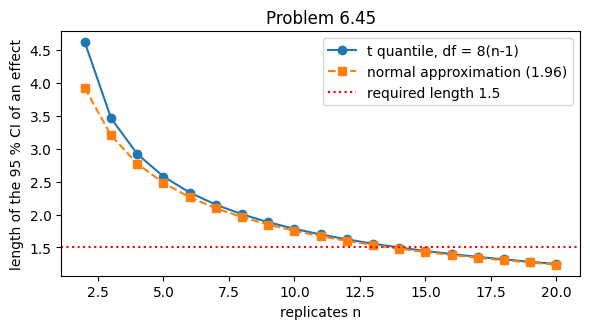

In [74]:
# 6.45: CI length of an effect as a function of the number of replicates n (sigma^2 = 4, 2^3 design)
sigma2, k, L_max = 4.0, 3, 1.5
rows = []
for n in range(2, 21):
    se = np.sqrt(sigma2 / (n * 2**(k - 2)))
    df_e = 2**k * (n - 1)
    rows.append({"n": n, "runs": n * 2**k, "df_E": df_e, "se(effect)": se, "t(0.975, df_E)": stats.t.ppf(0.975, df_e),
                 "length (t)": 2 * stats.t.ppf(0.975, df_e) * se, "length (normal)": 2 * 1.96 * se})
tab645 = pd.DataFrame(rows).set_index("n")
display(tab645.round(4))

n_normal = int(np.ceil(2 * (1.96 / (L_max / 2))**2))
n_t = int(tab645.index[tab645["length (t)"] <= L_max][0])
print(f"normal approximation: n >= 2 (1.96 / 0.75)^2 = {2 * (1.96 / 0.75)**2:.2f}  ->  n = {n_normal}")
print(f"exact t quantile:     smallest n with length <= {L_max} is n = {n_t} "
      f"(length {tab645.loc[n_t, 'length (t)']:.3f}; with n = {n_t - 1}: {tab645.loc[n_t - 1, 'length (t)']:.3f})")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(tab645.index, tab645["length (t)"], "o-", label="t quantile, df = 8(n-1)")
ax.plot(tab645.index, tab645["length (normal)"], "s--", label="normal approximation (1.96)")
ax.axhline(L_max, color="red", ls=":", label="required length 1.5")
ax.set(xlabel="replicates n", ylabel="length of the 95 % CI of an effect", title="Problem 6.45")
ax.legend(); plt.tight_layout(); plt.show()

With $n = 13$ replicates the interval is still too long (1.557 with the $t$ quantile, 1.538 with the normal approximation); with
$n = 14$ it is 1.499 (exact, $t_{0.025, 104} = 1.983$) and 1.482 (normal). Both approaches therefore require

$$n = 14 \text{ replicates, i.e. } 14 \cdot 8 = 112 \text{ runs}.$$

The $t$-correction hardly matters because the error degrees of freedom are large ($8(n-1) \ge 100$); the normal approximation
gives the same answer and is barely optimistic (for $n = 14$ the exact length 1.499 just meets the requirement). The large
number of runs is the price of a very precise requirement: the half-width 0.75 is only $0.375\,\sigma$.

**Conclusions (Problem 6.45)**

* $L = 2\, t_{0.025, 8(n-1)} \sqrt{2/n} \le 1.5$ gives $n = 14$ replicates (112 runs); the normal approximation gives the same
  $n = 14$ ($n \ge 13.7$).